# 3. From reference labels to classified objects

Segment imagery, measure objects, sample labels from a reference map, compare
classifiers with spatial validation, and evaluate in a separate test area.

This notebook runs independently with the small Chesapeake sample included in
OBIA. No data download is needed. From a repository checkout, install
`python -m pip install -e ".[notebooks]"`, then launch `jupyter lab`.
See the [sample data and setup guide](https://obia.sefa.ai/examples/) for
provenance, class codes, and source terms.

Run the cells from top to bottom. Files go into this notebook's subdirectory of
`example_outputs/`; rerunning replaces those example files. All OBIA band selections
use **zero-based numeric indices** into the loaded raster.

[Download this notebook](03_classification.ipynb)

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

from obia.datasets import chesapeake_sample
from obia.handlers.geotif import open_geotiff

import joblib
from matplotlib.colors import ListedColormap, BoundaryNorm
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

from obia.classification import classify, split_objects
from obia.features import extract_features
from obia.segmentation import create_segments
from obia.utils.utils import label_segments

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11})
output_dir = Path("example_outputs") / "03_classification"
output_dir.mkdir(parents=True, exist_ok=True)

## Load the sample imagery

The bundled training crop contains real aerial imagery and an aligned land-cover
reference map. It is 1024 × 1024 pixels at 1 m resolution in EPSG:26918.
Band values are stored as unsigned bytes, from 0 to 255, rather than calibrated
reflectance. We retain bands in their original order, indexed 0–3.

`open_geotiff()` returns OBIA's `Image` class: an array plus its CRS, transform,
and pixel-validity mask. Its optional `bands=` argument uses Rasterio's one-based
file numbering; subsequent OBIA selections are zero-based.

Loaded array: (1024, 1024, 4); CRS: EPSG:26918
Source tile: m_3807625_sw_18_1


,reference_class
code,
1,water
2,tree canopy / forest
3,low vegetation / field
4,barren land
5,impervious (other)
6,impervious (road)


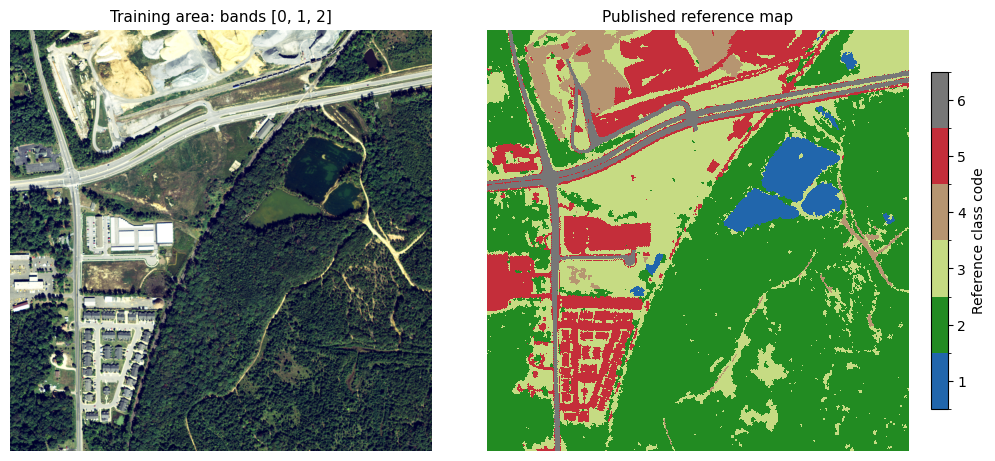

In [2]:
sample = chesapeake_sample("train")
image = open_geotiff(sample["image"])
image.rasterio_obj.close()  # Loaded arrays and spatial metadata remain available.
with rasterio.open(sample["reference"]) as src:
    reference = src.read(1)
class_names = sample["class_names"]
print(f"Loaded array: {image.img_data.shape}; CRS: {image.crs}")
print(f"Source tile: {sample['metadata']['tile_id']}")
class_cmap = ListedColormap(["#2166ac", "#228b22", "#c6db83", "#b69571", "#c42e3a", "#777777"])
class_norm = BoundaryNorm(np.arange(0.5, 7.5), class_cmap.N)
display(pd.Series(class_names, name="reference_class").rename_axis("code").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
axes[0].imshow(image.to_image([0, 1, 2]))
axes[0].set_title("Training area: bands [0, 1, 2]")
plot = axes[1].imshow(reference, cmap=class_cmap, norm=class_norm, interpolation="nearest")
axes[1].set_title("Published reference map")
fig.colorbar(plot, ax=axes[1], ticks=list(class_names), label="Reference class code", shrink=0.8)
for ax in axes:
    ax.set_axis_off()
plt.show()

## Segment and measure

Segment only the imagery. Use the same settings and feature definitions later
for the test area. The explicit feature list excludes reference codes, object
IDs, coordinates, and previous predictions. The normalized difference uses
stored image values, not calibrated reflectance.

In [3]:
def measure_objects(image):
    polygons = create_segments(
        image, segmentation_bands=[0, 1, 2, 3], method="slic",
        n_segments=2500, compactness=0.3, sigma=0.6, convert2lab=False,
    )
    return extract_features(
        polygons, image, bands=[0, 1, 2, 3], spectral=("mean", "std"), percentiles=(),
        indices={"normalized_difference": (3, 0)}, shape=("area", "circularity"),
    )

objects = measure_objects(image)
feature_columns = [
    "b0_mean", "b1_mean", "b2_mean", "b3_mean", "b0_std", "b3_std",
    "index_normalized_difference_b3_b0_mean", "shape_area", "shape_circularity",
]
print(f"{len(objects)} objects; {len(feature_columns)} selected features")

2400 objects; 9 selected features


## Transfer reference-map samples to objects

Take a point every 8 pixels and read its class from the reference raster.
These are samples from an existing map, not independent field observations.
For your own project, load surveyed or interpreted points with a `class` column
using `gpd.read_file("labels.gpkg").to_crs(objects.crs)`.

`label_segments()` retains objects whose sampled points agree. Conflicting and
unlabelled objects stay in the prediction map but are excluded from fitting and
scoring. Agreement among sampled points does not guarantee every pixel in an
object has the same class; excluding mixed objects also makes evaluation easier.

In [4]:
def sample_labels(objects, image, reference, class_names):
    rows, cols = np.mgrid[4:reference.shape[0]:8, 4:reference.shape[1]:8]
    rows, cols = rows.ravel(), cols.ravel()
    included = np.isin(reference[rows, cols], list(class_names))
    rows, cols = rows[included], cols[included]
    xs, ys = rasterio.transform.xy(image.transform, rows, cols)
    points = gpd.GeoDataFrame(
        {"class": [class_names[int(code)] for code in reference[rows, cols]]},
        geometry=gpd.points_from_xy(xs, ys), crs=image.crs,
    )
    labelled, mixed_ids = label_segments(objects, points)
    return labelled, mixed_ids, points

training, mixed_ids, labelled_points = sample_labels(objects, image, reference, class_names)
print(f"Labelled objects: {len(training)}; conflicting objects excluded: {len(mixed_ids)}")
display(training.feature_class.value_counts().rename("labelled_objects").to_frame())
labelled_points.to_file(output_dir / "reference_samples.gpkg", driver="GPKG")

Labelled objects: 1576; conflicting objects excluded: 824


,labelled_objects
feature_class,
tree canopy / forest,968
low vegetation / field,282
impervious (other),174
barren land,62
water,55
impervious (road),35


## Inspect spatial validation before fitting

Reserve whole 128 m blocks within the training crop and exclude training blocks
whose objects come within 10 m of validation objects. These distances illustrate
the API on a small crop; choose distances for the spatial dependence and intended
prediction area in your own study.

`test_size=0.2` reserves 20% of occupied blocks, not objects. Here the split's
`test` subset is used for **validation** during model comparison. Buffering removes
whole affected training blocks, which can discard many objects. Inspect the class
counts: a few objects of a rare class do not provide strong evidence of performance.
The separate upstream test crop remains unused until the final evaluation.

For real site or field IDs, use `method="grouped", groups="site_id"`. The
[validation guide](https://obia.sefa.ai/usage/validation/) explains sampling units,
buffers, and map accuracy assessment, with references to Roberts et al. (2017)
and Wadoux et al. (2021).

subset,train,validation,excluded
feature_class,,,
barren land,30,9,23
impervious (other),11,33,130
impervious (road),3,9,23
low vegetation / field,51,50,181
tree canopy / forest,356,176,436
water,7,21,27


{'n_train': 458, 'n_test': 298, 'n_excluded': 820}


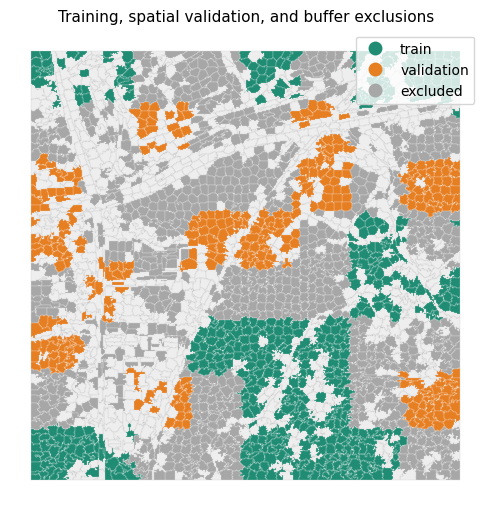

In [5]:
partition = split_objects(
    training, method="spatial", block_size=128, buffer_distance=10,
    test_size=0.2, random_state=42,
)
display(partition.class_counts.rename(columns={"test": "validation"}))
print({key: partition.metadata[key] for key in ("n_train", "n_test", "n_excluded")})

fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
objects.plot(ax=ax, color="#eeeeee", edgecolor="#bbbbbb", linewidth=0.15)
assignments = partition.assignments.assign(
    subset=partition.assignments.subset.replace({"test": "validation"}),
)
assignments.plot(
    ax=ax, column="subset", categorical=True, categories=["train", "validation", "excluded"],
    cmap=ListedColormap(["#218c74", "#e67e22", "#a7a7a7"]), legend=True,
    edgecolor="white", linewidth=0.15,
)
ax.set_title("Training, spatial validation, and buffer exclusions")
ax.set_axis_off()
plt.show()
partition.assignments.to_file(output_dir / "validation_split.gpkg", driver="GPKG")

## Compare classifiers on the same validation split

XGBoost is included with OBIA. Every model below uses the same objects and features.
Automatic scaling for logistic regression is fitted only on training rows.
Choose the model with the highest validation balanced accuracy: the mean recall
across classes. Overall agreement alone can hide poor performance on rare classes.

These scores measure agreement with the reference map among unambiguous sampled
objects. They do not estimate whole-map accuracy, and this tiny subset is not a
reproduction of the published Chesapeake benchmark.

In [6]:
methods = {
    "Random forest": ("rf", {"n_estimators": 100, "random_state": 42, "n_jobs": 1}),
    "Logistic regression": ("logistic_regression", {"max_iter": 1000}),
    "Histogram boosting": ("hist_gradient_boosting", {
        "max_iter": 100, "min_samples_leaf": 10, "random_state": 42,
    }),
    "XGBoost": ("xgboost", {
        "n_estimators": 100, "max_depth": 3, "random_state": 42, "n_jobs": 1,
    }),
}
results, scores = {}, []
for name, (method, parameters) in methods.items():
    result = classify(
        objects, training, method=method, feature_columns=feature_columns,
        split=partition, compute_reports=True, **parameters,
    )
    results[name] = result
    cm = result.confusion_matrix
    scores.append({"model": name, "validation_objects": int(cm.sum()),
                   "reference_agreement": np.trace(cm) / cm.sum(),
                   "balanced_accuracy": np.mean(np.diag(cm) / cm.sum(axis=1))})
scores = pd.DataFrame(scores).set_index("model")
selected_name = scores.balanced_accuracy.idxmax()
display(scores)
print(f"Selected using validation only: {selected_name}")

,validation_objects,reference_agreement,balanced_accuracy
model,,,
Random forest,298,0.859060,0.676372
Logistic regression,298,0.835570,0.628977
Histogram boosting,298,0.855705,0.721518
XGBoost,298,0.855705,0.674756


Selected using validation only: Histogram boosting


                        precision    recall  f1-score   support

           barren land       0.47      0.89      0.62         9
    impervious (other)       0.80      0.48      0.60        33
     impervious (road)       0.21      0.33      0.26         9
low vegetation / field       0.88      0.74      0.80        50
  tree canopy / forest       0.93      0.98      0.95       176
                 water       0.95      0.90      0.93        21

              accuracy                           0.86       298
             macro avg       0.71      0.72      0.69       298
          weighted avg       0.87      0.86      0.86       298



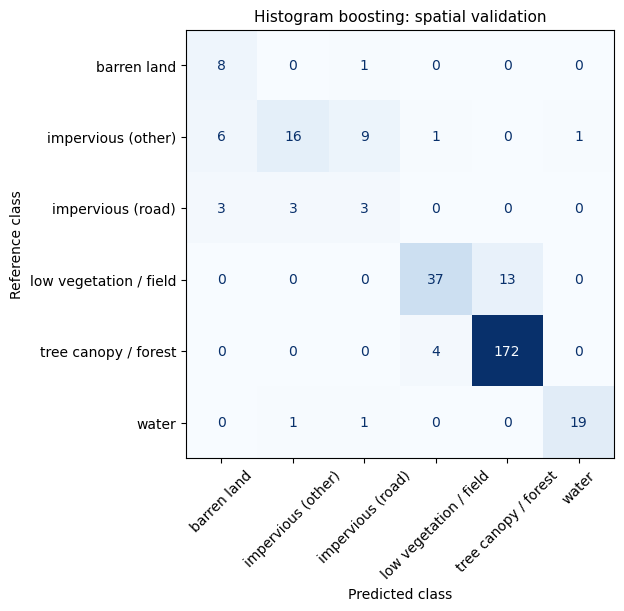

In [7]:
evaluated = results[selected_name]
print(evaluated.report)
fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
ConfusionMatrixDisplay(evaluated.confusion_matrix, display_labels=evaluated.classes).plot(
    ax=ax, colorbar=False, cmap="Blues", xticks_rotation=45,
)
ax.set_title(f"{selected_name}: spatial validation")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Reference class")
plt.show()

## Use a custom classifier pipeline

A custom pipeline owns its preprocessing. This one can impute missing numeric
values, scale features, and fit a linear SVM. OBIA clones and fits it on the
training partition. `LinearSVC` does not provide class probabilities, so its
`prediction_margin` is missing; ordinary class predictions still work.

In [8]:
pipeline = make_pipeline(
    SimpleImputer(strategy="median"), StandardScaler(), LinearSVC(random_state=42, max_iter=10000),
)
svm_result = classify(
    objects, training, method=pipeline, feature_columns=feature_columns,
    split=partition,
)
assert svm_result.probabilities is None
svm_result.classified[["segment_id", "predicted_class", "prediction_margin"]].head()

,segment_id,predicted_class,prediction_margin
0,15,barren land,NaN
1,16,tree canopy / forest,NaN
2,9,barren land,NaN
3,5,tree canopy / forest,NaN
4,4,tree canopy / forest,NaN


## Fit the selected model and evaluate the separate test area

Now load the crop from the publisher's test partition. Extract identical features
and sample its reference map using the same rule. The explicit split fits all
labelled objects from the training area and evaluates only the test area.
No test labels enter training or the earlier model selection.

`stratify=False` preserves this predefined split even when a class has no
unambiguous test objects. Training must still contain every class. Read support
counts alongside scores; an absent test class has no measured recall.

The two crops differ in land cover, and their reference map can contain errors or
date mismatches. A single small test area cannot establish regional performance.

subset,train,test,excluded
feature_class,,,
barren land,62,0,0
impervious (other),174,33,0
impervious (road),35,4,0
low vegetation / field,282,1274,0
tree canopy / forest,968,515,0
water,55,13,0


Test objects with conflicting sampled labels excluded: 627
                        precision    recall  f1-score   support

           barren land       0.00      0.00      0.00         0
    impervious (other)       0.54      0.58      0.56        33
     impervious (road)       0.00      0.00      0.00         4
low vegetation / field       0.83      0.98      0.90      1274
  tree canopy / forest       0.93      0.51      0.66       515
                 water       1.00      0.31      0.47        13

              accuracy                           0.83      1839
             macro avg       0.55      0.40      0.43      1839
          weighted avg       0.85      0.83      0.82      1839



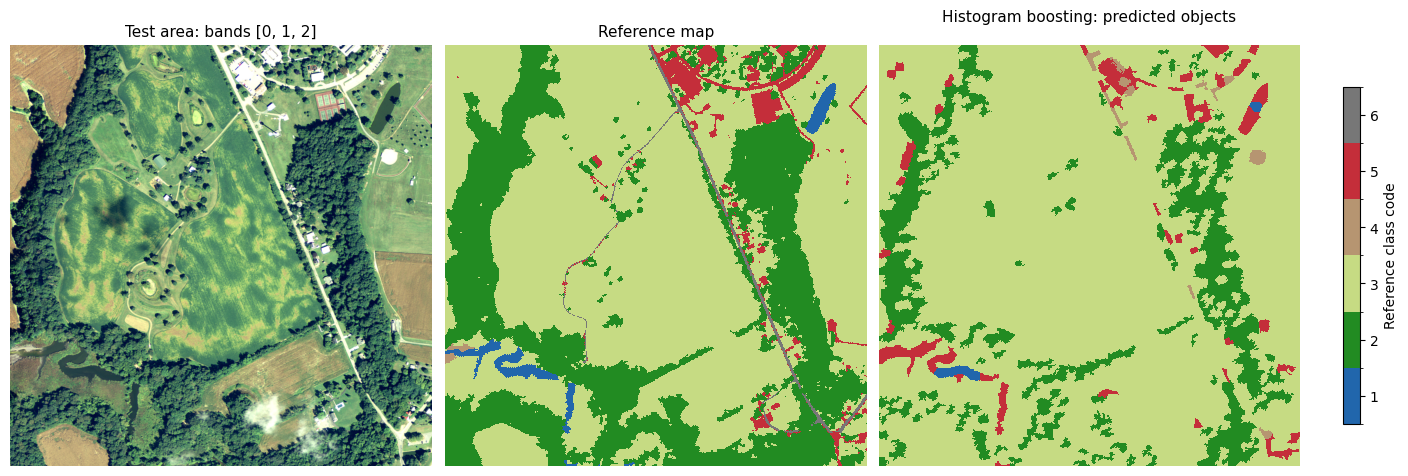

In [9]:
test_sample = chesapeake_sample("test")
test_image = open_geotiff(test_sample["image"])
test_image.rasterio_obj.close()
with rasterio.open(test_sample["reference"]) as src:
    test_reference = src.read(1)
test_objects = measure_objects(test_image)
test_labels, test_mixed, _ = sample_labels(test_objects, test_image, test_reference, class_names)
labelled = gpd.GeoDataFrame(pd.concat([
    training.assign(site_id="train"), test_labels.assign(site_id="test"),
], ignore_index=True), crs=objects.crs)
final_split = split_objects(
    labelled, method="explicit", groups="site_id", stratify=False,
    train_indices=labelled.site_id.eq("train").to_numpy(),
    test_indices=labelled.site_id.eq("test").to_numpy(),
)
display(final_split.class_counts)
method, parameters = methods[selected_name]
final = classify(
    test_objects, labelled, method=method, feature_columns=feature_columns,
    split=final_split, compute_reports=True, **parameters,
)
print(f"Test objects with conflicting sampled labels excluded: {len(test_mixed)}")
print(final.report)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout="constrained")
axes[0].imshow(test_image.to_image([0, 1, 2]))
axes[0].set_title("Test area: bands [0, 1, 2]")
axes[1].imshow(test_reference, cmap=class_cmap, norm=class_norm, interpolation="nearest")
axes[1].set_title("Reference map")
codes_by_name = {name: code for code, name in class_names.items()}
final.classified.assign(class_code=final.classified.predicted_class.map(codes_by_name)).plot(
    column="class_code", ax=axes[2], cmap=class_cmap, norm=class_norm,
)
axes[2].set_title(f"{selected_name}: predicted objects")
minx, miny, maxx, maxy = test_objects.total_bounds
axes[2].set_xlim(minx, maxx)
axes[2].set_ylim(miny, maxy)
fig.colorbar(plt.cm.ScalarMappable(norm=class_norm, cmap=class_cmap), ax=axes[1:],
             ticks=list(class_names), label="Reference class code", shrink=0.8)
for ax in axes:
    ax.set_axis_off()
plt.show()

## Save the map and reuse the fitted model

Save feature order with the model. For another scene, extract the same features
with the same band order and settings. Here we reload the model and check that
it reproduces the predictions for the test objects. The saved model was fitted
only on the training area.

`prediction_margin` is the gap between the two largest class probabilities.
Small gaps indicate ambiguity; margins are not calibrated accuracy estimates.

In [10]:
final.classified.to_file(output_dir / "classified_objects.gpkg", layer="objects", driver="GPKG")
joblib.dump({"model": final.model, "feature_columns": final.feature_columns},
            output_dir / "classifier.joblib")
saved = joblib.load(output_dir / "classifier.joblib")
predictions = saved["model"].predict(test_objects.loc[:, list(saved["feature_columns"])])
np.testing.assert_array_equal(predictions, final.classified.predicted_class)
saved_objects = gpd.read_file(output_dir / "classified_objects.gpkg", layer="objects")
assert len(saved_objects) == len(test_objects)
print(f"Saved classified polygons and a reusable classifier to {output_dir}")

Saved classified polygons and a reusable classifier to example_outputs/03_classification


Try other methods or features using only the training-area validation split.
Once you change choices in response to test results, that area becomes part of
model development; reserve a new independent area for final evaluation.

The [classification guide](https://obia.sefa.ai/usage/classification/) covers
method parameters, preprocessing, probabilities, and model explanations.